[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mlatcl/multilogue/blob/main/notebooks/03_cluster.ipynb)

# Shared topic space — soft MPPCA, harden views, lenses

### [Neil D. Lawrence](http://inverseprobability.com), University of Cambridge

### 2026-10-18

**Abstract**: Once phrases exist, we place them in one embedding space. Soft-throughout
Address (CIP-0017) fits a **mixture of probabilistic PCAs**: $k$-means only
initialises component means; soft responsibilities $r_{ik}$ are the primary
topic state. Hard labels and exemplars are a *late view* for LLM labelling and
lens prompts. This notebook teaches that split and shows a PCA view as a
diagnostic — not as the generative story for the phrases.


In [1]:
#@title Setup (run first)
# Infrastructure only: install or locate multilogue, prepare figure directory.
# Scientific imports live in later cells.

import sys, subprocess, pathlib

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "matplotlib", "pandas", "numpy", "scikit-learn", "pyyaml", "pot",
        "git+https://github.com/mlatcl/multilogue.git",
    ])
else:
    try:
        import multilogue  # noqa: F401
    except ImportError:
        _here = pathlib.Path.cwd().resolve()
        for _cand in (_here, _here.parent, *_here.parents):
            if (_cand / "pyproject.toml").is_file() and (_cand / "multilogue").is_dir():
                if str(_cand) not in sys.path:
                    sys.path.insert(0, str(_cand))
                break

from multilogue.notebook import setup

FIG = setup(figures_dir="outputs/notebook_figures")
print("Figures →", FIG)


Figures → /Users/neil/mlatcl/multilogue/notebooks/outputs/notebook_figures


# Introduction

Hard $k$-means gives every phrase a single topic label. Soft-throughout instead
keeps a distribution over topics. Multilogue's [`mppca_fit`](https://mlatcl.github.io/multilogue/api/mppca/)
uses $k$-means only to seed means, then EM under a **fixed** topic noise
$\sigma^2_{\mathrm{topic}}$ (independent of the lens-level $\sigma^2$ in
notebook 08).

Labels name topics; lenses group topics into coarser framings. Both LLM steps
consume a **harden view** (MAP labels / top-mass exemplars) — *format-blind* —
so the taxonomy is not fitted to the comparison we later want to make.


## Soft topics (MPPCA)

Topic $\sigma^2$ is fixed for the run (default `DEFAULT_TOPIC_SIGMA2`). Soft
responsibilities are checkpointed as the geometry; MAP labels are derived when
a discrete interface is required.


## PCA as a viewing device

The scatter below projects embeddings onto the first two principal components.
Classical PCA is a *view*, not the generative model. Soft lens memberships and
document EMD on soft histograms live in notebook 08.


In [2]:
from IPython.display import display
import numpy as np
from multilogue.llm import StageRunner
from multilogue.cluster import (
    Embedder, make_label_work, make_lens_work, resolve_lenses,
)
from multilogue.mppca import (
    DEFAULT_TOPIC_SIGMA2,
    mppca_fit,
    responsibilities_to_labels,
    example_phrases_for_soft_topics,
)
from multilogue import viz


In [3]:
import os
os.environ.setdefault("MULTILOGUE_ACCESS_YES", "1")
from multilogue.experiment import load_cimt_format_pair
from multilogue.extract import phrases_from_units

units, cimt_meta = load_cimt_format_pair(max_units_per=40)
if units is None:
    raise RuntimeError(
        "CIMT Access failed: "
        + str(cimt_meta.get("error", "unknown"))
        + ". Need network once to populate MULTILOGUE_DATAPATH / ~/.cache/multilogue."
    )
print(cimt_meta)
phrases = phrases_from_units(units, extra_fields=["group", "format"])
print(f"{len(units)} units → {len(phrases)} phrases (unit-as-phrase; LLM extract optional)")


{'dialogue_process': 'Cycling-Dialogue-Bonn', 'survey_process': 'Survey-Bonn', 'source': 'cimt', 'n_units': 80, 'n_dialogue': 40, 'n_survey': 40, 'n_docs': 41}
80 units → 80 phrases (unit-as-phrase; LLM extract optional)


In [4]:
from multilogue.clients import (
    resolve_study_client, TOPIC_LABEL_PROMPT, TOPIC_LABEL_SYSTEM,
)
from multilogue.config import load_dotenv

root = FIG.parent
env_path = load_dotenv()
client, models, client_kind = resolve_study_client(
    log_path=root / "logs" / "llm.jsonl",
)
print(
    f"LLM client: {client_kind} · embed={models['embed']} · label={models['label']}"
    + (f" · .env={env_path}" if env_path else " · .env=(not found)")
)


LLM client: openai · embed=text-embedding-3-small · label=gpt-4.1-mini · .env=/Users/neil/mlatcl/multilogue/.env


In [5]:
# client_kind comes from resolve_study_client (openai, or fake only if forced).
_runner_kw = {"max_workers": 2}
if client_kind == "fake":
    _runner_kw["sleep"] = lambda _: None
runner = StageRunner(root / "ckpt_cl", root / "logs_cl", **_runner_kw)
k = min(4, max(2, len(phrases) // 3))
embedder = Embedder(root / "emb", client, model=models["embed"])
E = np.asarray(embedder(phrases.phrase.tolist()), float)
fit = mppca_fit(E, k=k, sigma2=DEFAULT_TOPIC_SIGMA2, seed=0)
R = fit["responsibilities"]
means = fit["means"]
labels = responsibilities_to_labels(R)
phrases = phrases.copy()
phrases["cluster"] = labels  # harden view for bars / lens map only
# Cosine similarity to MAP topic mean (diagnostic)
valid = labels >= 0
phrases["centroid_sim"] = 0.0
phrases.loc[valid, "centroid_sim"] = (E[valid] * means[labels[valid]]).sum(1)
print(f"topic σ²={fit['sigma2']}; EM iters={fit['n_iter']}")
print(f"mean max responsibility: {R.max(axis=1).mean():.3f}")
(root / "clusters").mkdir(parents=True, exist_ok=True)
np.save(root / "clusters" / "responsibilities.npy", R)
np.save(root / "clusters" / "topic_means.npy", means)


topic σ²=0.01; EM iters=3
mean max responsibility: 1.000


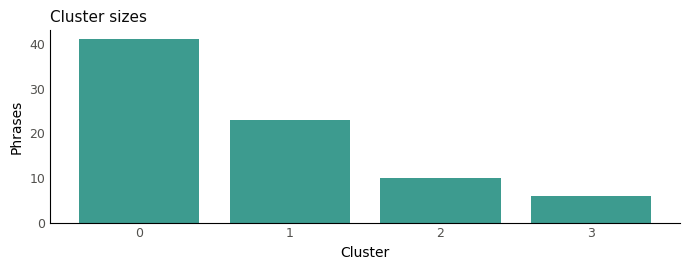

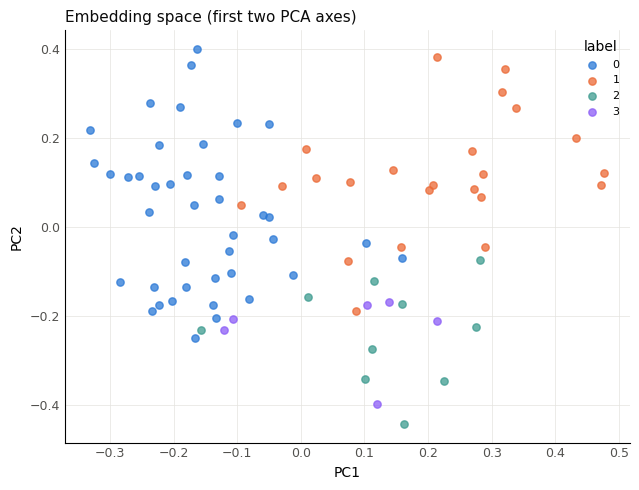

PosixPath('/Users/neil/mlatcl/multilogue/notebooks/outputs/notebook_figures/03_pca_clusters.png')

In [6]:
viz.cluster_size_bars(phrases, path=FIG / "03_cluster_sizes.png")
viz.embedding_scatter(E, phrases["cluster"], path=FIG / "03_pca_clusters.png")


Cluster-size bars use the MAP harden view so empty topics are visible. Soft
geometry remains in $R$. Hopeless overlap in the PCA scatter suggests revisiting
$k$ or the phrase set before interpreting shares — that decision is **Assess**,
not a format-gap maximisation.


## Assess — interactive subject grain (Bishop–Tipping)

Choosing how many subjects belong in the catalogue is closer to “what is the
human grain of this corpus?” than to “which quote threshold?”. Following
Bishop & Tipping’s hierarchical visualisation (TPAMI 1998), the analyst sees
**both**:

1. **Geometry** — the **local** $U_q$ plane of the topic you are considering
   splitting (not a global PCA of the whole embedding cloud). Soft mass on
   that component sets point opacity; the panel updates when you change the
   split target.
2. **Semantics** — an LLM catalogue of the same bags (exemplars + names).

Neither view replaces the other. Merge / split / keep is human feedback — not
automatic maximisation of a study metric $\ell$. Under *assess without the
question*, this loop is Assess; lenses, format gap, and multiverse under a
**locked** catalogue are Address.

**Catalogue first:** the shell names every topic once (LLM) so the table shows
real subject labels — not ``topic 0``. The widget has a **label prompt** text
box and a **model** dropdown (keep ``<<PHRASES>>``). **Apply & re-name all**
pushes the new prompt into the live labelling work and re-labels every topic.

Select ≥2 topics in **Merge** to preview the *merged* $U_q$ with the originals
listed (means + ellipses); **Propose merge** then Accept (or Undo). A split is
likewise a *proposal*: child means in the **parent** $U_q$. Accept when happy.


In [7]:
import os
from multilogue.subject_grain_shell import SubjectGrainShell, ipywidgets_available

# label_client= lets the widget Textarea / model Dropdown rebuild label_work
shell = SubjectGrainShell(
    E, fit, phrases, phrase_col="phrase", seed=0,
    label_client=client,
    label_system=TOPIC_LABEL_SYSTEM,
    label_prompt=TOPIC_LABEL_PROMPT,
    label_model=models["label"],
    name_initial=True,
)
print("initial catalogue labels:", {j: shell.labels[j] for j in shell.topic_ids()})
# Widgets for live try-combinations; CI / smoke force the scripted path.
use_widgets = (
    ipywidgets_available()
    and os.environ.get("MULTILOGUE_SUBJECT_GRAIN_WIDGETS", "1") != "0"
)
if use_widgets:
    print(
        "Layer B: select merge candidates (live merged U_q) / Propose split → Accept"
    )
    shell.display()
else:
    print("Layer A scripted path (no widgets / MULTILOGUE_SUBJECT_GRAIN_WIDGETS=0)")
    display(shell.catalogue())
    # Local U_q of the topic under split consideration (Bishop–Tipping channel)
    focus = 0
    shell.fit_view(focus=focus, path=FIG / "03_topic_fit_view.png", show=True)
    # Demo propose-merge (merged U_q + originals) then undo
    if shell.k >= 3:
        shell.merge([0, 1])
        mid = int(shell.pending_proposal["merged_id"])
        print(
            "after propose merge: k =", shell.k,
            "merged_id =", mid,
            "sources =", shell.pending_proposal.get("source_labels"),
        )
        shell.fit_view(
            focus=mid, path=FIG / "03_topic_fit_after_merge.png", show=True
        )
        display(shell.catalogue())
        shell.undo()
        print("after undo: k =", shell.k)
    # Demo proposed split: parent U_q + child means, lineage in catalogue
    if shell.k >= 2:
        parent = 0
        parent_name = shell.labels.get(parent, f"topic {parent}")
        shell.split(parent)
        print(
            "proposed split of", repr(parent_name),
            "→ children", shell.proposed_topic_ids(),
            "parent_of", {c: shell.parent_of.get(c) for c in shell.proposed_topic_ids()},
            "pending=", shell.pending_proposal is not None,
        )
        shell.fit_view(
            focus=shell.proposed_topic_ids()[0],
            path=FIG / "03_proposed_split.png",
            show=True,
        )
        display(shell.catalogue())
        print("child labels after split:", {
            c: shell.labels[c] for c in shell.proposed_topic_ids()
        })
        shell.accept_proposal()
        print("accepted; parent_of =", shell.parent_of)
    lock = shell.lock(
        path=root / "clusters" / "subject_grain_lock.json",
        k_multiverse="hold",
    )
    print("locked subject grain:", lock["primary_k"], lock["k_multiverse"])
    display(lock)


initial catalogue labels: {0: 'Improving Bicycle Infrastructure', 1: 'Community Safety and Infrastructure Issues', 2: 'Traffic and Cycling Accessibility Issues', 3: 'Cyclist Access and Safety Concerns'}
Layer B: select merge candidates (live merged U_q) / Propose split → Accept


Lock before Address spend: the artefact records `primary_k` and a hold /
$\pm 1$ multiverse policy. Wide $k$ grids belong in an explicit one-factor
resolution sweep — not in the default factorial multiverse (see notebook 09).


## Blind labels and lenses (harden view)

Exemplars are ranked by soft mass on each topic; the LLM never sees raw
responsibility matrices. Researchers may edit the lens mapping afterwards — the
first pass stays blind. After a subject-grain lock, labels here name the
*locked* leaves.


In [8]:
# Re-bind fit / R from the shell if the scripted path ran; widgets leave `fit` as initial.
R = shell.responsibilities
fit = shell.fit
means = fit["means"]
k = shell.k
labels = responsibilities_to_labels(R)
phrases = phrases.copy()
phrases["cluster"] = labels
valid = labels >= 0
phrases["centroid_sim"] = 0.0
phrases.loc[valid, "centroid_sim"] = (E[valid] * means[labels[valid]]).sum(1)

cluster_units = example_phrases_for_soft_topics(
    phrases.phrase.tolist(), R, n_top=8, n_sample=2, seed=0,
)
# Drop empty components for labelling
cluster_units = [cu for cu in cluster_units if cu["examples"]]
from multilogue.clients import label_stage_fingerprint
lab = runner.run(
    "labels", cluster_units, lambda cu: cu["key"],
    make_label_work(
        client, system=TOPIC_LABEL_SYSTEM,
        prompt_template=TOPIC_LABEL_PROMPT, model=models["label"],
    ),
    label_stage_fingerprint(
        models["label"], system=TOPIC_LABEL_SYSTEM, prompt=TOPIC_LABEL_PROMPT,
    ),
    quiet=True,
)
names = {
    cu["cluster"]: lab.get(cu["key"], {}).get("label", f"cluster {cu['cluster']}")
    for cu in cluster_units
}
print(names)
cl_desc = "\n".join(
    f"{c}: {names.get(c, f'topic {c}')} — (mass {R[:, c].sum():.1f})" for c in range(k)
)
lens_runs = runner.run(
    "lenses", [1, 2], lambda r: str(r),
    make_lens_work(
        client, system="lens", prompt_template="Group:\n<<CLUSTERS>>",
        cluster_description=cl_desc, model=models["label"], k=k,
    ),
    f"lenses|{models['label']}", quiet=True,
)
mapping, edited = resolve_lenses(k, lens_runs)
phrases["lens"] = phrases["cluster"].map(mapping)
print("lens mapping:", mapping, "edited:", edited)


{0: 'Bicycle Infrastructure Improvements', 1: 'Community Safety and Infrastructure Issues', 2: 'Urban Traffic and Bicycle Access Issues', 3: 'Cycling and Pedestrian Pathways'}
lens mapping: {0: 'Other', 1: 'Other', 2: 'Other', 3: 'Other'} edited: False


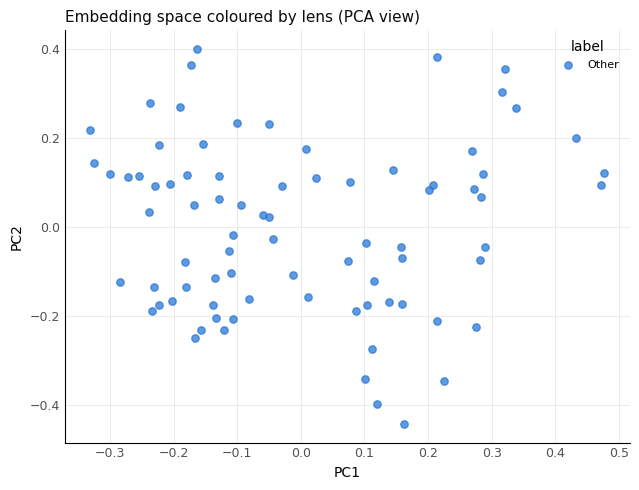

PosixPath('/Users/neil/mlatcl/multilogue/notebooks/outputs/notebook_figures/03_pca_lenses.png')

In [9]:
viz.embedding_scatter(
    E, phrases["lens"],
    title="Embedding space coloured by lens (PCA view)",
    path=FIG / "03_pca_lenses.png",
)


# Outlook

Soft responsibilities $R$ and topic means feed notebook 08 (soft histograms →
document EMD; soft lenses under a separate fixed $\sigma^2_{\mathrm{lens}}$).
Notebook 04 can still use MAP or lens columns for document-weighted shares; soft
composition is the CIP-0017 default for transport. Notebook 09 consumes a
**locked** subject grain under format-gap $\ell$ (multiverse holds $k$).
